In [28]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer


In [30]:

df = pd.read_csv("/Users/kierachiu/Documents/IDX Exchange/IDX-Exchange-Data-Science/02_cleaned_data.csv")

print("Dataset shape:", df.shape)
display(df.head())
print(df.columns.tolist())


Dataset shape: (106501, 20)


,LivingArea,BedroomsTotal,BathroomsTotalInteger,LotSizeSquareFeet,YearBuilt,Latitude,Longitude,ParkingTotal,PostalCode,FireplaceYN,NewConstructionYN,City,CountyOrParish,ViewYN,MLSAreaMajor,AttachedGarageYN,ClosePrice,CloseDate,closing_month,dataset_split
0,1810.0,3.0,3.0,5318.0,1988.0,33.157973,-117.253250,4.0,92081,True,False,Vista,San Diego,False,92081 - Vista,True,1040000.0,2025-07-31,2025-07,train
1,2987.0,3.0,3.0,12632.0,1954.0,33.803727,-116.534532,6.0,92264,True,False,Palm Springs,Riverside,True,334 - South End Palm Springs,True,2400000.0,2025-07-31,2025-07,train
2,2007.0,4.0,3.0,3600.0,1968.0,36.603859,-121.868261,2.0,93940,True,False,Monterey,Monterey,True,699 - Not Defined,True,1908500.0,2025-07-23,2025-07,train
3,2234.0,4.0,4.0,17248.0,1948.0,33.151355,-117.101143,2.0,92026,False,NaN,Escondido,San Diego,True,92026 - Escondido,True,1050000.0,2025-07-29,2025-07,train
4,2967.0,3.0,3.0,10200.0,2000.0,37.390272,-122.110274,1.0,94022,True,False,Los Altos,Santa Clara,False,699 - Not Defined,True,5900000.0,2025-07-31,2025-07,train


['LivingArea', 'BedroomsTotal', 'BathroomsTotalInteger', 'LotSizeSquareFeet', 'YearBuilt', 'Latitude', 'Longitude', 'ParkingTotal', 'PostalCode', 'FireplaceYN', 'NewConstructionYN', 'City', 'CountyOrParish', 'ViewYN', 'MLSAreaMajor', 'AttachedGarageYN', 'ClosePrice', 'CloseDate', 'closing_month', 'dataset_split']


In [31]:
# same split as in 03_baseline_model
summary = json.load(open("02_run_summary.json"))

best_X = summary["best_X"]
test_month = summary["test_month"]
low = summary["lower_threshold"]
high = summary["upper_threshold"]

# Define numeric features
numeric_features = [
    "LivingArea",
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LotSizeSquareFeet",
    "YearBuilt",
    "Latitude",
    "Longitude",
    "ParkingTotal"
]

# Define categorical features
categorical_features = [
    "PostalCode",
    "FireplaceYN",
    "NewConstructionYN",
    "City",
    "CountyOrParish",
    "ViewYN",
    "MLSAreaMajor",
    "AttachedGarageYN"
]

# Combine all features and define target
features = numeric_features + categorical_features
target = "ClosePrice"

# Load cleaned dataset from Week 3
df = pd.read_csv(
    "02_cleaned_data.csv",
    dtype={"PostalCode": "string"},
    parse_dates=["CloseDate"],
    low_memory=False
)

# Reuse the original train/test split
train = df[df["dataset_split"] == "train"].copy()
test = df[df["dataset_split"] == "test"].copy()

# Convert categorical values to strings and fill missing values
for d in (train, test):
    for c in categorical_features:
        d[c] = d[c].astype("string").fillna("Missing")

# Separate features (X) and target (y)
X_train = train[features]
y_train = train[target].to_numpy(float)

X_test = test[features]
y_test = test[target].to_numpy(float)

# Display dataset information
print(f"Training window: {best_X} months | Test month: {test_month}")
print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Training price bounds: ${low:,.0f} to ${high:,.0f}")

Training window: 9 months | Test month: 2026-04
Train: (94162, 16) | Test: (12339, 16)
Training price bounds: $190,000 to $8,750,000


### New features:
1. Property Age
2. Bedroom-to-Bathroom Ratio

In [32]:
# Property Age

# Convert YearBuilt to numeric values
train["YearBuilt"] = pd.to_numeric(
    train["YearBuilt"], errors="coerce"
)

test["YearBuilt"] = pd.to_numeric(
    test["YearBuilt"], errors="coerce"
)

# Calculate property age at the time of sale
train["Property_Age"] = (
    train["CloseDate"].dt.year - train["YearBuilt"]
)

test["Property_Age"] = (
    test["CloseDate"].dt.year - test["YearBuilt"]
)

# Replace invalid ages with missing values
for data in [train, test]:
    data.loc[
        (data["Property_Age"] < 0) |
        (data["Property_Age"] > 200),
        "Property_Age"
    ] = np.nan

# Display examples
display(
    train[["YearBuilt", "CloseDate", "Property_Age"]].head(10)
)

,YearBuilt,CloseDate,Property_Age
0,1988.0,2025-07-31,37.0
1,1954.0,2025-07-31,71.0
2,1968.0,2025-07-23,57.0
3,1948.0,2025-07-29,77.0
4,2000.0,2025-07-31,25.0
5,1952.0,2025-07-30,73.0
6,2006.0,2025-07-31,19.0
7,1941.0,2025-07-30,84.0
8,1972.0,2025-07-31,53.0
9,1959.0,2025-07-24,66.0


In [33]:
# Bedroom-to-Bathroom Ratio

# Convert bedroom and bathroom counts to numeric
for data in [train, test]:

    data["BedroomsTotal"] = pd.to_numeric(
        data["BedroomsTotal"], errors="coerce"
    )

    data["BathroomsTotalInteger"] = pd.to_numeric(
        data["BathroomsTotalInteger"], errors="coerce"
    )

    # Calculate bedroom-to-bathroom ratio
    data["Bed_Bath_Ratio"] = (
        data["BedroomsTotal"] /
        data["BathroomsTotalInteger"].replace(0, np.nan)
    )

    # Replace infinite values with NaN
    data["Bed_Bath_Ratio"] = data[
        "Bed_Bath_Ratio"
    ].replace([np.inf, -np.inf], np.nan)

# Display examples
display(
    train[
        [
            "BedroomsTotal",
            "BathroomsTotalInteger",
            "Bed_Bath_Ratio"
        ]
    ].head(10)
)

,BedroomsTotal,BathroomsTotalInteger,Bed_Bath_Ratio
0,3.0,3.0,1.000000
1,3.0,3.0,1.000000
2,4.0,3.0,1.333333
3,4.0,4.0,1.000000
4,3.0,3.0,1.000000
5,3.0,3.0,1.000000
6,4.0,3.0,1.333333
7,3.0,1.0,3.000000
8,4.0,3.0,1.333333
9,3.0,2.0,1.500000


In [34]:
# Update Model Feature List

# Add engineered features to numeric features
new_numeric_features = [
    "Property_Age",
    "Bed_Bath_Ratio"
]

numeric_features = numeric_features + new_numeric_features

# Update complete feature list
features = numeric_features + categorical_features

# Rebuild training and testing inputs
X_train = train[features].copy()
X_test = test[features].copy()

# Confirm new features were added
print("Total features:", len(features))

print("\nNew engineered features:")
print(new_numeric_features)

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# Display new feature values
display(
    X_train[
        ["Property_Age", "Bed_Bath_Ratio"]
    ].head()
)

Total features: 18

New engineered features:
['Property_Age', 'Bed_Bath_Ratio']

Training data shape: (94162, 18)
Testing data shape: (12339, 18)


,Property_Age,Bed_Bath_Ratio
0,37.0,1.000000
1,71.0,1.000000
2,57.0,1.333333
3,77.0,1.000000
4,25.0,1.000000


In [35]:
# Verify Feature Engineering

print("\nNew features in training data:")
print(
    X_train[
        ["Property_Age", "Bed_Bath_Ratio"]
    ].describe()
)

print("\nMissing values:")
print(
    X_train[
        ["Property_Age", "Bed_Bath_Ratio"]
    ].isnull().sum()
)

print("\nFeature list:")
print(features)

print("\nTraining rows:", len(X_train))
print("Testing rows:", len(X_test))

=== WEEK 6 FEATURE ENGINEERING CHECK ===

New features in training data:
       Property_Age  Bed_Bath_Ratio
count  94106.000000    94136.000000
mean      49.430578        1.459163
std       27.535866        0.470318
min        0.000000        0.000000
25%       27.000000        1.000000
50%       49.000000        1.500000
75%       70.000000        1.500000
max      172.000000        7.500000

Missing values:
Property_Age      56
Bed_Bath_Ratio    26
dtype: int64

Feature list:
['LivingArea', 'BedroomsTotal', 'BathroomsTotalInteger', 'LotSizeSquareFeet', 'YearBuilt', 'Latitude', 'Longitude', 'ParkingTotal', 'Property_Age', 'Bed_Bath_Ratio', 'PostalCode', 'FireplaceYN', 'NewConstructionYN', 'City', 'CountyOrParish', 'ViewYN', 'MLSAreaMajor', 'AttachedGarageYN']

Training rows: 94162
Testing rows: 12339


In [41]:
%pip install geopandas pyogrio shapely

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.7/24.7 MB 8.8 MB/s  0:00:028.9 MB/s eta 0:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 9.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 9.8 MB/s  0:00:00m 10.3 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [geopandas]━ 3/4 [geopandas]
Note: you may need to restart the kernel to use updated packages.


In [47]:
from pathlib import Path

# Locate the downloaded school district file

# Show the folder Jupyter is using
print("Current working directory:")
print(Path.cwd())

# Set the folder containing your data
data_folder = Path(
    "/Users/kierachiu/Documents/IDX Exchange/IDX-Exchange-Data-Science/Data"
)

# Find GeoJSON files in the Data folder
geojson_files = list(data_folder.glob("*.geojson"))

print("\nGeoJSON files found:")

for file in geojson_files:
    print(file.name)

if len(geojson_files) == 0:
    print("\nNo GeoJSON files found.")
    print("Check that the downloaded file is in:")
    print(data_folder)


Current working directory:
/Users/kierachiu/Documents/IDX Exchange/IDX-Exchange-Data-Science

GeoJSON files found:
California_School_District_Areas_2024-25.geojson


In [48]:
# Load California school district boundaries

# Select the downloaded GeoJSON file
assert len(geojson_files) == 1, (
    "Expected exactly one GeoJSON file. "
    "Check the filenames printed above."
)

school_file = geojson_files[0]

# Load geographic data
school_districts = gpd.read_file(school_file)

# Check dataset dimensions
print("School district dataset loaded!")

print("\nDataset shape:")
print(school_districts.shape)

print("\nAvailable columns:")
print(school_districts.columns.tolist())

print("\nCoordinate reference system:")
print(school_districts.crs)

# Display first five rows
display(school_districts.head())


School district dataset loaded!

Dataset shape:
(937, 54)

Available columns:
['OBJECTID', 'Year', 'FedID', 'CDCode', 'CDSCode', 'CountyName', 'DistrictName', 'DistrictType', 'GradeLow', 'GradeHigh', 'GradeLowCensus', 'GradeHighCensus', 'AssistStatus', 'CongressUS', 'SenateCA', 'AssemblyCA', 'UpdateNotes', 'EnrollTotal', 'EnrollCharter', 'EnrollNonCharter', 'AAcount', 'AApct', 'AIcount', 'AIpct', 'AScount', 'ASpct', 'FIcount', 'FIpct', 'HIcount', 'HIpct', 'PIcount', 'PIpct', 'WHcount', 'WHpct', 'MRcount', 'MRpct', 'NRcount', 'NRpct', 'ELcount', 'ELpct', 'FOScount', 'FOSpct', 'HOMcount', 'HOMpct', 'MIGcount', 'MIGpct', 'SWDcount', 'SWDpct', 'SEDcount', 'SEDpct', 'DistrctAreaSqMi', 'Shape__Area', 'Shape__Length', 'geometry']

Coordinate reference system:
EPSG:4326


,OBJECTID,Year,FedID,CDCode,CDSCode,CountyName,DistrictName,DistrictType,GradeLow,GradeHigh,...,MIGcount,MIGpct,SWDcount,SWDpct,SEDcount,SEDpct,DistrctAreaSqMi,Shape__Area,Shape__Length,geometry
0,1,2024-25,0601770,0161119,01611190000000,Alameda,Alameda Unified,Unified,PK,12,...,0,0.0,1356,12.6,3958,36.7,11.248939,4.755489e+07,56522.982683,"MULTIPOLYGON (((-122.22678 37.72651, -122.2267..."
1,2,2024-25,0601860,0161127,01611270000000,Alameda,Albany City Unified,Unified,PK,12,...,0,0.0,357,9.7,1184,32.1,1.789984,7.096327e+06,12696.382797,"POLYGON ((-122.28671 37.89852, -122.28673 37.8..."
2,3,2024-25,0604740,0161143,01611430000000,Alameda,Berkeley Unified,Unified,PK,12,...,0,0.0,1111,12.1,2686,29.3,10.434329,4.364648e+07,43695.341538,"POLYGON ((-122.25606 37.89834, -122.25607 37.8..."
3,4,2024-25,0607800,0161150,01611500000000,Alameda,Castro Valley Unified,Unified,PK,12,...,0,0.0,1113,11.6,3728,39.0,66.885571,2.838285e+08,142492.767565,"MULTIPOLYGON (((-122.01375 37.64265, -122.0114..."
4,5,2024-25,0612630,0161168,01611680000000,Alameda,Emery Unified,Unified,PK,12,...,0,0.0,81,13.7,412,69.8,1.273929,5.363392e+06,13741.272894,"POLYGON ((-122.29663 37.8311, -122.29778 37.83..."


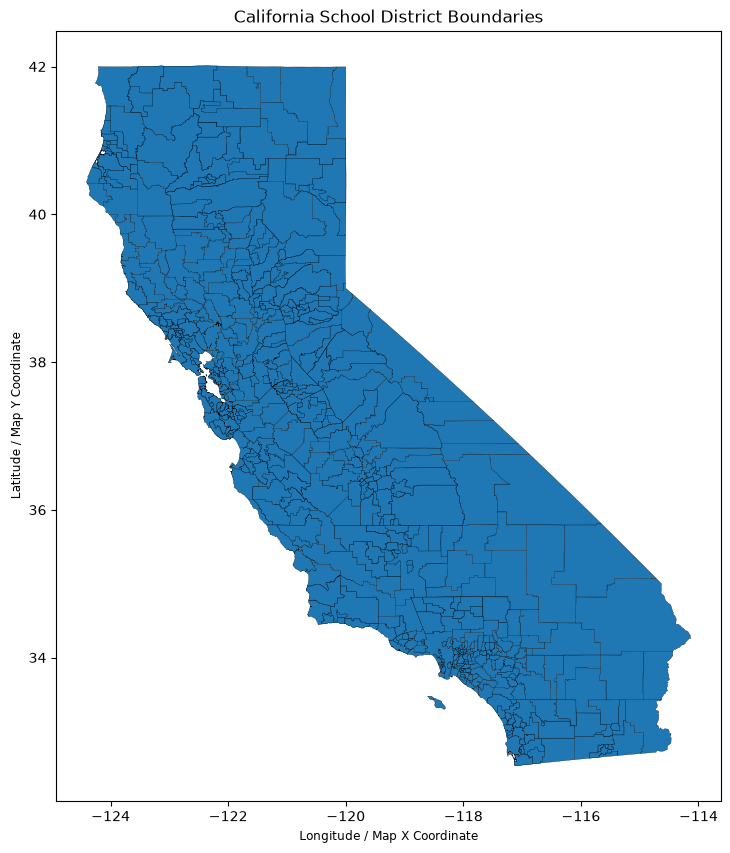

In [49]:
# Visualize school district boundaries
# Plot the geographic boundaries
ax = school_districts.plot(
    figsize=(10, 10),
    edgecolor="black",
    linewidth=0.2
)

plt.title("California School District Boundaries")
plt.xlabel("Longitude / Map X Coordinate")
plt.ylabel("Latitude / Map Y Coordinate")

plt.show()


In [62]:
# Examine school district types

print("School District Types:")
print(school_districts["DistrictType"].value_counts(dropna=False))

print("\nNumber of unique districts:")
print(school_districts["DistrictName"].nunique())

print("\nMissing district names:")
print(school_districts["DistrictName"].isna().sum())

display(
    school_districts[
        ["DistrictName", "DistrictType", "CountyName"]
    ].head(10)
)

School District Types:
DistrictType
Elementary    516
Unified       345
High           76
Name: count, dtype: int64

Number of unique districts:
926

Missing district names:
0


,DistrictName,DistrictType,CountyName
0,Alameda Unified,Unified,Alameda
1,Albany City Unified,Unified,Alameda
2,Berkeley Unified,Unified,Alameda
3,Castro Valley Unified,Unified,Alameda
4,Emery Unified,Unified,Alameda
5,Fremont Unified,Unified,Alameda
6,Hayward Unified,Unified,Alameda
7,Livermore Valley Joint Unified,Unified,Alameda
8,Mountain House Elementary,Elementary,Alameda
9,Newark Unified,Unified,Alameda


In [63]:
# Check property coordinates

for name, data in [("Training", train), ("Testing", test)]:

    print(f"\n{name} Dataset")

    print("Total properties:", len(data))

    print("Missing latitude:", data["Latitude"].isna().sum())
    print("Missing longitude:", data["Longitude"].isna().sum())

    print("\nCoordinate examples:")
    display(data[["Latitude", "Longitude"]].head())


Training Dataset
Total properties: 94162
Missing latitude: 135
Missing longitude: 135

Coordinate examples:


,Latitude,Longitude
0,33.157973,-117.253250
1,33.803727,-116.534532
2,36.603859,-121.868261
3,33.151355,-117.101143
4,37.390272,-122.110274



Testing Dataset
Total properties: 12339
Missing latitude: 76
Missing longitude: 76

Coordinate examples:


,Latitude,Longitude
94162,37.302662,-121.890526
94163,34.288017,-119.305144
94164,37.242612,-122.014066
94165,37.774756,-122.287192
94166,33.612301,-117.650788


In [64]:
# Convert properties into geographic points

# Make copies so original data remains unchanged
train_geo = train.copy()
test_geo = test.copy()

# Ensure coordinates are numeric
for data in [train_geo, test_geo]:

    data["Latitude"] = pd.to_numeric(
        data["Latitude"], errors="coerce"
    )

    data["Longitude"] = pd.to_numeric(
        data["Longitude"], errors="coerce"
    )

    # Replace invalid coordinates with missing values
    valid = (
        data["Latitude"].between(-90, 90) &
        data["Longitude"].between(-180, 180)
    )

    data.loc[~valid, ["Latitude", "Longitude"]] = np.nan

# Convert training data to GeoDataFrame
train_geo = gpd.GeoDataFrame(
    train_geo,
    geometry=gpd.points_from_xy(
        train_geo["Longitude"],
        train_geo["Latitude"]
    ),
    crs="EPSG:4326"
)

# Convert testing data to GeoDataFrame
test_geo = gpd.GeoDataFrame(
    test_geo,
    geometry=gpd.points_from_xy(
        test_geo["Longitude"],
        test_geo["Latitude"]
    ),
    crs="EPSG:4326"
)

print("Training geographic data:", train_geo.shape)
print("Testing geographic data:", test_geo.shape)

print("\nTraining CRS:", train_geo.crs)
print("Testing CRS:", test_geo.crs)

display(
    train_geo[
        ["Latitude", "Longitude", "geometry"]
    ].head()
)

Training geographic data: (94162, 23)
Testing geographic data: (12339, 23)

Training CRS: EPSG:4326
Testing CRS: EPSG:4326


,Latitude,Longitude,geometry
0,33.157973,-117.253250,POINT (-117.25325 33.15797)
1,33.803727,-116.534532,POINT (-116.53453 33.80373)
2,36.603859,-121.868261,POINT (-121.86826 36.60386)
3,33.151355,-117.101143,POINT (-117.10114 33.15136)
4,37.390272,-122.110274,POINT (-122.11027 37.39027)


In [66]:
# Verify geographic conversion

print("\nOriginal training rows:", len(train))
print("Geographic training rows:", len(train_geo))

print("\nOriginal testing rows:", len(test))
print("Geographic testing rows:", len(test_geo))

# Make sure no rows were lost
assert len(train) == len(train_geo)
assert len(test) == len(test_geo)


Original training rows: 94162
Geographic training rows: 94162

Original testing rows: 12339
Geographic testing rows: 12339


In [67]:
# Prepare school district boundaries

# Keep only the columns needed for geographic matching
districts_clean = school_districts[
    ["CDCode", "DistrictName", "DistrictType", "geometry"]
].copy()

# Make sure coordinates use the same reference system
districts_clean = districts_clean.to_crs("EPSG:4326")

# Remove missing or empty geographic shapes
districts_clean = districts_clean[
    districts_clean.geometry.notna() &
    ~districts_clean.geometry.is_empty
].copy()

print("School districts ready for matching!")
print("Total districts:", len(districts_clean))

display(districts_clean.head())

School districts ready for matching!
Total districts: 937


,CDCode,DistrictName,DistrictType,geometry
0,0161119,Alameda Unified,Unified,"MULTIPOLYGON (((-122.22678 37.72651, -122.2267..."
1,0161127,Albany City Unified,Unified,"POLYGON ((-122.28671 37.89852, -122.28673 37.8..."
2,0161143,Berkeley Unified,Unified,"POLYGON ((-122.25606 37.89834, -122.25607 37.8..."
3,0161150,Castro Valley Unified,Unified,"MULTIPOLYGON (((-122.01375 37.64265, -122.0114..."
4,0161168,Emery Unified,Unified,"POLYGON ((-122.29663 37.8311, -122.29778 37.83..."


In [68]:
# Spatial join properties with school districts

# Assign priority to district types
district_priority = {
    "Unified": 1,
    "Elementary": 2,
    "High": 3
}

districts_clean["Priority"] = (
    districts_clean["DistrictType"].map(district_priority)
)

def match_school_districts(properties, districts):

    # Keep the original property row position
    points = properties.copy()
    points["_property_row"] = np.arange(len(points))

    # Exclude missing coordinates from geographic matching
    valid = (
        points["Latitude"].notna() &
        points["Longitude"].notna()
    )

    # Perform spatial join
    joined = gpd.sjoin(
        points.loc[valid],
        districts[
            ["CDCode", "DistrictName",
             "DistrictType", "Priority", "geometry"]
        ],
        how="left",
        predicate="intersects"
    )

    # Choose the highest-priority matching district
    joined = joined.sort_values(
        ["_property_row", "Priority", "CDCode"],
        na_position="last"
    )

    joined = joined.drop_duplicates(
        subset="_property_row",
        keep="first"
    )

    # Preserve original property rows and their order
    district_matches = joined.set_index("_property_row")[
        ["CDCode", "DistrictName", "DistrictType"]
    ]

    result = points.drop(columns=["_property_row"]).copy()

    result["School_District_Code"] = (
        pd.Series(
            np.arange(len(result)),
            index=result.index
        ).map(district_matches["CDCode"]).values
    )

    result["School_District_Name"] = (
        pd.Series(
            np.arange(len(result)),
            index=result.index
        ).map(district_matches["DistrictName"]).values
    )

    result["School_District_Type"] = (
        pd.Series(
            np.arange(len(result)),
            index=result.index
        ).map(district_matches["DistrictType"]).values
    )

    return result


# Match training properties
train_with_schools = match_school_districts(
    train_geo,
    districts_clean
)

# Match testing properties
test_with_schools = match_school_districts(
    test_geo,
    districts_clean
)

print("Spatial joins completed!")

Spatial joins completed!


In [69]:
# Validate school district matching

for name, original, matched in [
    ("Training", train, train_with_schools),
    ("Testing", test, test_with_schools)
]:

    print(f"\n{name} dataset")

    print("Original rows:", len(original))
    print("Matched rows:", len(matched))

    matched_count = matched[
        "School_District_Code"
    ].notna().sum()

    print("Properties with district:", matched_count)

    print(
        "Match rate:",
        f"{matched_count / len(matched) * 100:.2f}%"
    )

    assert len(original) == len(matched), (
        "Row count changed during spatial join!"
    )

print("\nSUCCESS: Original row counts preserved!")

display(
    train_with_schools[
        [
            "Latitude",
            "Longitude",
            "School_District_Name",
            "School_District_Type"
        ]
    ].head(10)
)


Training dataset
Original rows: 94162
Matched rows: 94162
Properties with district: 93992
Match rate: 99.82%

Testing dataset
Original rows: 12339
Matched rows: 12339
Properties with district: 12258
Match rate: 99.34%

SUCCESS: Original row counts preserved!


,Latitude,Longitude,School_District_Name,School_District_Type
0,33.157973,-117.253250,Vista Unified,Unified
1,33.803727,-116.534532,Palm Springs Unified,Unified
2,36.603859,-121.868261,Monterey Peninsula Unified,Unified
3,33.151355,-117.101143,Escondido Union,Elementary
4,37.390272,-122.110274,Los Altos Elementary,Elementary
5,37.443300,-122.196536,Menlo Park City Elementary,Elementary
6,33.715394,-117.004719,Hemet Unified,Unified
7,34.186403,-118.297054,Burbank Unified,Unified
8,37.218889,-121.874141,San Jose Unified,Unified
9,37.684132,-122.477853,Jefferson Elementary,Elementary


In [70]:
# Add school district feature to model data

# Create copies of the existing 18-feature datasets
train_school = train.copy()
test_school = test.copy()

# Add school district codes as categorical values
train_school["School_District"] = (
    train_with_schools["School_District_Code"]
    .astype("string")
    .fillna("Unknown")
    .to_numpy()
)

test_school["School_District"] = (
    test_with_schools["School_District_Code"]
    .astype("string")
    .fillna("Unknown")
    .to_numpy()
)

# Confirm the new column exists
print("School district feature added successfully!")

print("\nTraining dataset:")
display(
    train_school[
        ["BedroomsTotal", "LivingArea", "School_District"]
    ].head()
)

print("\nMissing school district values:")
print(train_school["School_District"].isna().sum())
print(test_school["School_District"].isna().sum())

School district feature added successfully!

Training dataset:


,BedroomsTotal,LivingArea,School_District
0,3.0,1810.0,3768452
1,3.0,2987.0,3367173
2,4.0,2007.0,2766092
3,4.0,2234.0,3768098
4,3.0,2967.0,4369518



Missing school district values:
0
0


In [92]:
# Update feature list to include school districts

# Preserve original feature lists
school_numeric_features = numeric_features.copy()

school_categorical_features = (
    categorical_features + ["School_District"]
)

# Combine all features
school_features = (
    school_numeric_features + school_categorical_features
)

# Create updated model inputs
X_train_school = train_school[school_features].copy()
X_test_school = test_school[school_features].copy()

print("Total features:", len(school_features))
print("Numeric features:", len(school_numeric_features))
print("Categorical features:", len(school_categorical_features))

print("\nTraining shape:", X_train_school.shape)
print("Testing shape:", X_test_school.shape)

assert len(X_train_school) == len(y_train)
assert len(X_test_school) == len(y_test)

Total features: 19
Numeric features: 10
Categorical features: 9

Training shape: (94162, 19)
Testing shape: (12339, 19)


In [72]:

# Define the original and engineered feature sets

from sklearn.base import clone

old_numeric_features = [
    "LivingArea",
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LotSizeSquareFeet",
    "YearBuilt",
    "Latitude",
    "Longitude",
    "ParkingTotal"
]

old_categorical_features = [
    "PostalCode",
    "FireplaceYN",
    "NewConstructionYN",
    "City",
    "CountyOrParish",
    "ViewYN",
    "MLSAreaMajor",
    "AttachedGarageYN"
]

engineered_numeric_features = old_numeric_features + [
    "Property_Age",
    "Bed_Bath_Ratio"
]

engineered_categorical_features = (
    old_categorical_features + ["School_District"]
)

# Each configuration specifies its own source data.
# Old: original 16 features
# Engineered: 19 features (including school district)

feature_sets = {
    "Original (16)": {
        "train": train,
        "test": test,
        "numeric": old_numeric_features,
        "categorical": old_categorical_features
    },
    "Engineered (19)": {
        "train": train_school,
        "test": test_school,
        "numeric": engineered_numeric_features,
        "categorical": engineered_categorical_features
    }
}

def make_preprocessor(numeric_cols, categorical_cols):
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="Missing"
        )),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore"
        ))
    ])

    return ColumnTransformer([
        ("num", numeric_pipe, numeric_cols),
        ("cat", categorical_pipe, categorical_cols)
    ])

def get_feature_data(config):
    cols = config["numeric"] + config["categorical"]
    X_tr = config["train"][cols].copy()
    X_te = config["test"][cols].copy()

    for c in config["categorical"]:
        X_tr[c] = X_tr[c].astype("object").fillna("Missing").astype(str)
        X_te[c] = X_te[c].astype("object").fillna("Missing").astype(str)

    return X_tr, X_te

for name, config in feature_sets.items():
    X_tr, X_te = get_feature_data(config)
    print(f"{name}: Train {X_tr.shape}, Test {X_te.shape}")

assert len(train) == len(train_school) == len(y_train)
assert len(test) == len(test_school) == len(y_test)
assert np.all(y_train > 0) and np.all(y_test > 0)


Original (16): Train (94162, 16), Test (12339, 16)
Engineered (19): Train (94162, 19), Test (12339, 19)


In [93]:
# Compare original vs engineered features with identical settings

def make_estimator(model_name):
    if model_name == "Linear Regression":
        return LinearRegression()

    if model_name == "Decision Tree":
        return DecisionTreeRegressor(
            max_depth=10,
            min_samples_leaf=5,
            random_state=42
        )

    if model_name == "Random Forest":
        return RandomForestRegressor(
            n_estimators=200,
            max_depth=15,
            min_samples_leaf=3,
            random_state=42,
            n_jobs=-1
        )

    raise ValueError(f"Unknown model: {model_name}")

def calculate_metrics(actual, predicted):
    return {
        "R²": r2_score(actual, predicted),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MdAPE (%)": 100 * np.median(
            np.abs(predicted - actual) / actual
        )
    }

model_names = [
    "Linear Regression",
    "Decision Tree",
    "Random Forest"
]

comparison_rows = []
trained_models = {}
model_predictions = {}

for feature_name, config in feature_sets.items():

    X_tr, X_te = get_feature_data(config)

    for model_name in model_names:
        print(f"Training: {model_name} | {feature_name}")

        model = Pipeline([
            ("preprocessor", make_preprocessor(
                config["numeric"], config["categorical"]
            )),
            ("model", make_estimator(model_name))
        ])

        # Maintain the notebook's original log-target
        # approach for linear regression only.
        if model_name == "Linear Regression":
            model.fit(X_tr, np.log(y_train))
            train_pred = np.exp(model.predict(X_tr))
            test_pred = np.exp(model.predict(X_te))
        else:
            model.fit(X_tr, y_train)
            train_pred = model.predict(X_tr)
            test_pred = model.predict(X_te)

        train_metrics = calculate_metrics(y_train, train_pred)
        test_metrics = calculate_metrics(y_test, test_pred)

        comparison_rows.append({
            "Model": model_name,
            "Feature Set": feature_name,
            "Train R²": train_metrics["R²"],
            "Test R²": test_metrics["R²"],
            "R² Gap": train_metrics["R²"] - test_metrics["R²"],
            "MAE": test_metrics["MAE"],
            "RMSE": test_metrics["RMSE"],
            "MdAPE (%)": test_metrics["MdAPE (%)"]
        })

        trained_models[(feature_name, model_name)] = model
        model_predictions[(feature_name, model_name)] = test_pred

comparison = pd.DataFrame(comparison_rows)

display(comparison.round(4))

comparison.to_csv(
    "06_original_vs_engineered_models.csv",
    index=False
)

Training: Linear Regression | Original (16)
Training: Decision Tree | Original (16)
Training: Random Forest | Original (16)
Training: Linear Regression | Engineered (19)
Training: Decision Tree | Engineered (19)
Training: Random Forest | Engineered (19)


,Model,Feature Set,Train R²,Test R²,R² Gap,MAE,RMSE,MdAPE (%)
0,Linear Regression,Original (16),0.6883,0.7582,-0.0699,197404.6139,488106.0251,9.9958
1,Decision Tree,Original (16),0.7992,0.7419,0.0572,288759.4963,504269.5627,16.2941
2,Random Forest,Original (16),0.9141,0.8455,0.0687,209565.4033,390223.4322,11.2798
3,Linear Regression,Engineered (19),0.7069,0.7651,-0.0583,195880.1301,481070.6852,9.8796
4,Decision Tree,Engineered (19),0.7964,0.7332,0.0632,293867.7411,512704.1733,16.4963
5,Random Forest,Engineered (19),0.9137,0.8425,0.0711,210787.0211,393888.0833,11.2957


,Model,Original R²,Engineered R²,R² Improvement,Original MAE,Engineered MAE,MAE Reduction ($)
0,Linear Regression,0.7582,0.7651,0.0069,197404.6139,195880.1301,1524.4838
1,Decision Tree,0.7419,0.7332,-0.0087,288759.4963,293867.7411,-5108.2447
2,Random Forest,0.8455,0.8425,-0.0029,209565.4033,210787.0211,-1221.6178


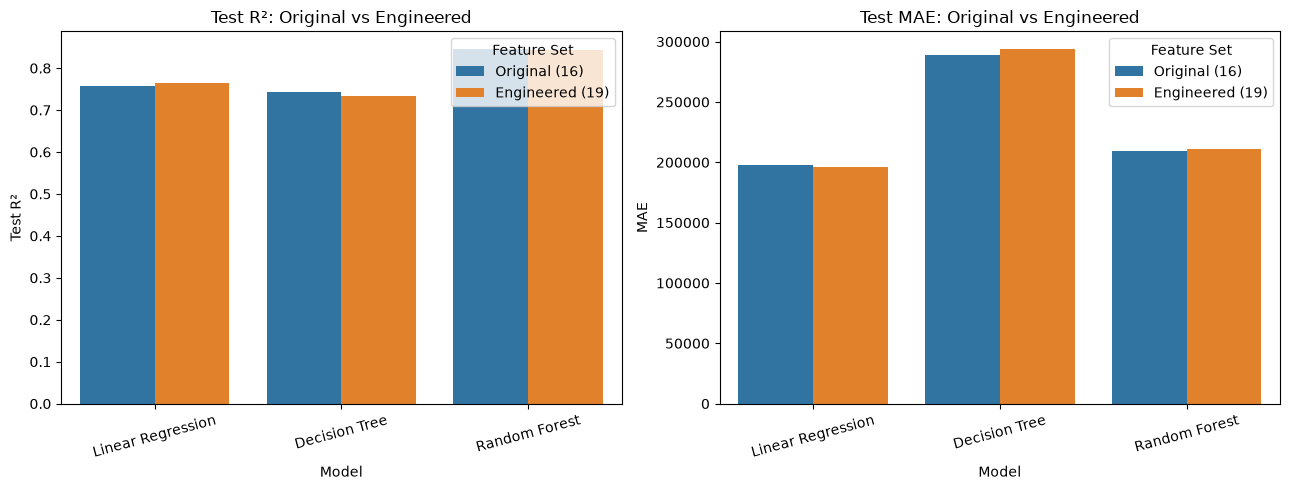

In [74]:
# Calculate improvement from feature engineering alone

original_results = comparison[
    comparison["Feature Set"] == "Original (16)"
].set_index("Model")

engineered_results = comparison[
    comparison["Feature Set"] == "Engineered (19)"
].set_index("Model")

feature_improvement = pd.DataFrame({
    "Original R²": original_results["Test R²"],
    "Engineered R²": engineered_results["Test R²"],
    "R² Improvement": (
        engineered_results["Test R²"] -
        original_results["Test R²"]
    ),
    "Original MAE": original_results["MAE"],
    "Engineered MAE": engineered_results["MAE"],
    "MAE Reduction ($)": (
        original_results["MAE"] -
        engineered_results["MAE"]
    )
}).reset_index()

display(feature_improvement.round(4))

# Visual comparison
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=comparison,
    x="Model",
    y="Test R²",
    hue="Feature Set",
    ax=axes[0]
)
axes[0].set_title("Test R²: Original vs Engineered")
axes[0].tick_params(axis="x", rotation=15)

sns.barplot(
    data=comparison,
    x="Model",
    y="MAE",
    hue="Feature Set",
    ax=axes[1]
)
axes[1].set_title("Test MAE: Original vs Engineered")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

feature_improvement.to_csv(
    "06_feature_engineering_improvement.csv",
    index=False
)


In [83]:
#  hyperparameter tuning: Decision Tree and Random Forest

from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.base import clone

engineered_config = feature_sets["Engineered (19)"]
X_tune, X_holdout = get_feature_data(engineered_config)

# Sort training data by closing date
sort_positions = np.argsort(
    pd.to_datetime(
        engineered_config["train"]["CloseDate"]
    ).to_numpy(),
    kind="stable"
)

X_tune_sorted = X_tune.iloc[sort_positions].reset_index(drop=True)
y_tune_sorted = np.asarray(y_train)[sort_positions]

cv = TimeSeriesSplit(n_splits=3)

tuning_preprocessor = make_preprocessor(
    engineered_config["numeric"],
    engineered_config["categorical"]
)

# Smaller search spaces for faster execution
parameter_spaces = {
    "Decision Tree": {
        "model__max_depth": [5, 10, 15, 20],
        "model__min_samples_leaf": [3, 5, 10],
        "model__min_samples_split": [2, 10]
    },
    "Random Forest": {
        "model__max_depth": [10, 15, 20],
        "model__min_samples_leaf": [3, 5, 10],
        "model__max_features": [0.6, 0.8, 1.0]
    }
}

tuning_searches = {}
tuning_rows = []

for model_name in ["Decision Tree", "Random Forest"]:

    print(f"\n=== TUNING {model_name.upper()} ===")

    if model_name == "Decision Tree":
        estimator = DecisionTreeRegressor(
            random_state=42
        )
    else:
        estimator = RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=1
        )

    pipeline = Pipeline([
        ("preprocessor", clone(tuning_preprocessor)),
        ("model", estimator)
    ])

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parameter_spaces[model_name],
        n_iter=5,
        scoring="r2",
        cv=cv,
        refit=True,
        random_state=42,
        n_jobs=-1,
        verbose=1
    )

    search.fit(X_tune_sorted, y_tune_sorted)

    tuning_searches[model_name] = search

    tuning_rows.append({
        "Model": model_name,
        "Best CV R²": search.best_score_,
        "Best Parameters": search.best_params_
    })

    print("Best CV R²:", round(search.best_score_, 4))
    print("Best Parameters:", search.best_params_)

tuning_summary = pd.DataFrame(tuning_rows)

print("\n=== TUNING SUMMARY ===")
display(tuning_summary)



=== TUNING DECISION TREE ===
Fitting 3 folds for each of 5 candidates, totalling 15 fits


Python(47966) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(47967) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(47968) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(47969) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(47970) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(47971) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(47972) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(47973) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(47974) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(47975) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


Best CV R²: 0.761
Best Parameters: {'model__min_samples_split': 2, 'model__min_samples_leaf': 10, 'model__max_depth': 15}

=== TUNING RANDOM FOREST ===
Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best CV R²: 0.8378
Best Parameters: {'model__min_samples_leaf': 3, 'model__max_features': 0.8, 'model__max_depth': 20}

=== TUNING SUMMARY ===


,Model,Best CV R²,Best Parameters
0,Decision Tree,0.761019,"{'model__min_samples_split': 2, 'model__min_sa..."
1,Random Forest,0.837787,"{'model__min_samples_leaf': 3, 'model__max_fea..."


In [79]:
# FAST evaluation of optimized models
# Evaluate on a sample of test properties
import time

# Use up to 5,000 test properties
sample_size = min(5000, len(X_holdout))

rng = np.random.default_rng(42)
sample_indices = rng.choice(
    len(X_holdout),
    size=sample_size,
    replace=False
)

X_test_sample = X_holdout.iloc[sample_indices]
y_test_sample = np.asarray(y_test)[sample_indices]

optimized_rows = []
optimized_models = {}
optimized_predictions = {}

for model_name, search in tuning_searches.items():

    print(f"Evaluating {model_name}...", flush=True)
    start = time.perf_counter()

    # Reuse already-trained model
    best_model = search.best_estimator_

    # Predict on smaller sample
    predictions = best_model.predict(X_test_sample)

    metrics = calculate_metrics(
        y_test_sample, predictions
    )

    optimized_rows.append({
        "Model": model_name,
        "Test R²": metrics["R²"],
        "MAE": metrics["MAE"],
        "RMSE": metrics["RMSE"],
        "MdAPE (%)": metrics["MdAPE (%)"],
        "CV R²": search.best_score_,
        "Best Depth": search.best_params_.get(
            "model__max_depth"
        )
    })

    optimized_models[model_name] = best_model
    optimized_predictions[model_name] = predictions

    print(
        f"{model_name} completed in "
        f"{time.perf_counter() - start:.1f} seconds",
        flush=True
    )

optimized_comparison = pd.DataFrame(optimized_rows)

print("\n=== SAMPLED TEST RESULTS ===")
print(f"Test properties evaluated: {sample_size:,}")
display(optimized_comparison.round(4))


Evaluating Decision Tree...
Decision Tree completed in 0.0 seconds

=== SAMPLED TEST RESULTS ===
Test properties evaluated: 5,000


,Model,Test R²,MAE,RMSE,MdAPE (%),CV R²,Best Depth
0,Decision Tree,0.7871,243480.4775,444867.4793,12.9989,0.7671,15


In [84]:

# Evaluate optimized Random Forest on the same 5,000 properties
if "Random Forest" in tuning_searches:

    start = time.perf_counter()

    rf_model = tuning_searches[
        "Random Forest"
    ].best_estimator_

    rf_predictions = rf_model.predict(X_test_sample)

    rf_metrics = calculate_metrics(
        y_test_sample,
        rf_predictions
    )

    rf_results = pd.DataFrame([{
        "Model": "Random Forest",
        "Test R²": rf_metrics["R²"],
        "MAE": rf_metrics["MAE"],
        "RMSE": rf_metrics["RMSE"],
        "MdAPE (%)": rf_metrics["MdAPE (%)"],
        "CV R²": tuning_searches[
            "Random Forest"
        ].best_score_,
        "Best Depth": tuning_searches[
            "Random Forest"
        ].best_params_.get("model__max_depth")
    }])

    optimized_comparison = pd.concat(
        [optimized_comparison, rf_results],
        ignore_index=True
    )

    optimized_models["Random Forest"] = rf_model
    optimized_predictions["Random Forest"] = rf_predictions

    print(
        "Random Forest completed in",
        round(time.perf_counter() - start, 2),
        "seconds"
    )

    display(rf_results.round(4))

else:
    print("Random Forest has not been tuned yet.")
    print("Run the Random Forest tuning cell first.")


Random Forest completed in 0.16 seconds


,Model,Test R²,MAE,RMSE,MdAPE (%),CV R²,Best Depth
0,Random Forest,0.8671,186724.9304,351522.6593,9.766,0.8378,20


In [91]:

# Final Comparison: Original vs Engineered and Optimized Models

# 1. Get original 16-feature model results
old_results = comparison[
    comparison["Feature Set"] == "Original (16)"
].copy()

# 2. Get engineered Linear Regression results
new_lr = comparison[
    (comparison["Feature Set"] == "Engineered (19)") &
    (comparison["Model"] == "Linear Regression")
].copy()

# 3. Get optimized Decision Tree and Random Forest results
optimized_results = []

for model_name in ["Decision Tree", "Random Forest"]:

    # Retrieve the optimized trained model
    model = tuning_searches[model_name].best_estimator_

    # Predict on the FULL test set, not the 5,000-row sample
    predictions = model.predict(X_holdout)

    metrics = calculate_metrics(y_test, predictions)

    optimized_results.append({
        "Model": model_name,
        "Test R²": metrics["R²"],
        "MAE": metrics["MAE"],
        "RMSE": metrics["RMSE"],
        "MdAPE (%)": metrics["MdAPE (%)"]
    })

optimized_results_df = pd.DataFrame(optimized_results)

# 4. Combine engineered LR and optimized tree models
new_results = pd.concat(
    [
        new_lr[
            ["Model", "Test R²", "MAE", "RMSE", "MdAPE (%)"]
        ],
        optimized_results_df
    ],
    ignore_index=True
)

# 5. Merge old and new results
metrics_to_compare = [
    "Model", "Test R²", "MAE", "RMSE", "MdAPE (%)"
]

final_comparison = pd.merge(
    old_results[metrics_to_compare],
    new_results[metrics_to_compare],
    on="Model",
    suffixes=("_Old", "_New")
)

# 6. Calculate improvements
final_comparison["R² Improvement"] = (
    final_comparison["Test R²_New"] -
    final_comparison["Test R²_Old"]
)

final_comparison["MAE Reduction ($)"] = (
    final_comparison["MAE_Old"] -
    final_comparison["MAE_New"]
)

final_comparison["RMSE Reduction ($)"] = (
    final_comparison["RMSE_Old"] -
    final_comparison["RMSE_New"]
)

final_comparison["MdAPE Reduction (pp)"] = (
    final_comparison["MdAPE (%)_Old"] -
    final_comparison["MdAPE (%)_New"]
)

# 7. Display final results
print("MODEL COMPARISON")

display(final_comparison.round(4))

# 8. Save comparison to CSV
final_comparison.to_csv(
    "06_final_model_comparison.csv",
    index=False
)

print("Final model comparison saved successfully!")


MODEL COMPARISON


,Model,Test R²_Old,MAE_Old,RMSE_Old,MdAPE (%)_Old,Test R²_New,MAE_New,RMSE_New,MdAPE (%)_New,R² Improvement,MAE Reduction ($),RMSE Reduction ($),MdAPE Reduction (pp)
0,Linear Regression,0.7582,197404.6139,488106.0251,9.9958,0.7651,195880.1301,481070.6852,9.8796,0.0069,1524.4838,7035.3399,0.1162
1,Decision Tree,0.7419,288759.4963,504269.5627,16.2941,0.7845,244699.2844,460776.5158,12.7620,0.0426,44060.2119,43493.0469,3.5321
2,Random Forest,0.8455,209565.4033,390223.4322,11.2798,0.8546,191560.5062,378562.0282,9.6479,0.0091,18004.8971,11661.4040,1.6319


Final model comparison saved successfully!
